# Step 3: Explore the Landslide4Sense data

Goal: open the satellite patches, see what each band shows, and understand the landslide masks before training anything.

**Before running:**
1. In Terminal (with `(geoai)` active): `conda install -c conda-forge h5py`
2. Download `TrainData` from https://zenodo.org/records/10463239 and unzip it into `~/geoai/data/` so you have `~/geoai/data/TrainData/img/` and `~/geoai/data/TrainData/mask/`
3. Put this notebook in `~/geoai/`, then run `cd ~/geoai && jupyter lab`

In [9]:
from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path.home() / "geoai" / "data" / "TrainData"
IMG_DIR = DATA_DIR / "img"
MASK_DIR = DATA_DIR / "mask"

img_files = sorted(IMG_DIR.glob("image_*.h5"), key=lambda p: int(p.stem.split("_")[1]))
print(f"Found {len(img_files)} image patches in {IMG_DIR}")
assert len(img_files) > 0, "No files found. Check that DATA_DIR points to the unzipped TrainData folder."

Found 3799 image patches in /Users/razbinkarkidoli/geoai/data/TrainData/img


## Load one patch
Each patch is 128x128 pixels with 14 bands: Sentinel-2 B1–B12, then slope and elevation (DEM).

In [10]:
BAND_NAMES = ["B1 coastal", "B2 blue", "B3 green", "B4 red", "B5 red edge 1", "B6 red edge 2",
              "B7 red edge 3", "B8 NIR", "B9 water vapor", "B10 cirrus", "B11 SWIR 1", "B12 SWIR 2",
              "Slope", "Elevation (DEM)"]

def read_h5(path):
    with h5py.File(path, "r") as f:
        key = list(f.keys())[0]
        return f[key][:]

def load_pair(i):
    img = read_h5(IMG_DIR / f"image_{i}.h5").astype(np.float32)
    mask = read_h5(MASK_DIR / f"mask_{i}.h5")
    return img, mask

with h5py.File(IMG_DIR / "image_1.h5", "r") as f:
    print("Keys inside an image file:", list(f.keys()))

img, mask = load_pair(1)
print("Image shape:", img.shape, img.dtype)
print("Mask shape:", mask.shape, "unique values:", np.unique(mask))

Keys inside an image file: ['img']
Image shape: (128, 128, 14) float32
Mask shape: (128, 128) unique values: [0 1]


## What the bands show
- **True color** (red, green, blue): what your eye would see
- **False color** (NIR, red, green): healthy vegetation glows red, bare soil from a landslide looks dull
- **NDVI**: vegetation index; landslides strip vegetation, so they show up as low values
- **Slope and DEM**: landslides happen on steep terrain

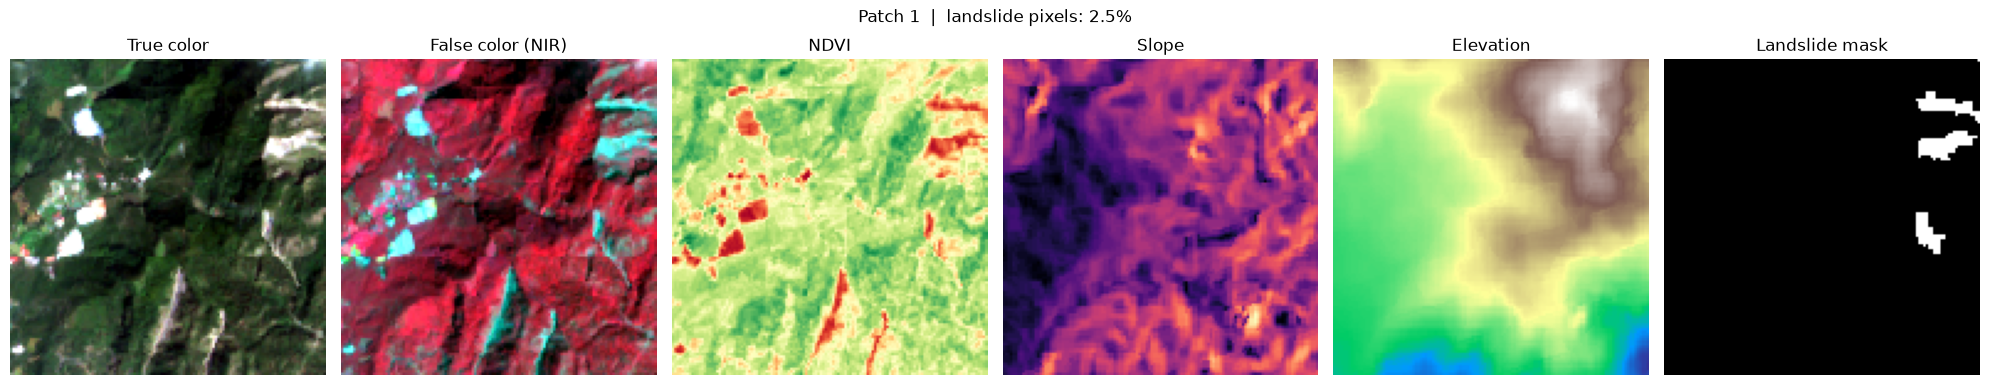

In [11]:
def stretch(x):
    lo, hi = np.percentile(x, (2, 98))
    return np.clip((x - lo) / (hi - lo + 1e-6), 0, 1)

def rgb(img, bands):
    return np.dstack([stretch(img[:, :, b]) for b in bands])

def ndvi(img):
    nir, red = img[:, :, 7], img[:, :, 3]
    return (nir - red) / (nir + red + 1e-6)

def show_patch(i):
    img, mask = load_pair(i)
    panels = [
        ("True color", rgb(img, [3, 2, 1]), None),
        ("False color (NIR)", rgb(img, [7, 3, 2]), None),
        ("NDVI", ndvi(img), "RdYlGn"),
        ("Slope", img[:, :, 12], "magma"),
        ("Elevation", img[:, :, 13], "terrain"),
        ("Landslide mask", mask, "gray"),
    ]
    fig, axes = plt.subplots(1, 6, figsize=(20, 4))
    for ax, (title, data, cmap) in zip(axes, panels):
        ax.imshow(data, cmap=cmap)
        ax.set_title(title)
        ax.axis("off")
    fig.suptitle(f"Patch {i}  |  landslide pixels: {mask.mean():.1%}")
    plt.tight_layout()
    plt.show()

show_patch(1)

## Find patches that actually contain landslides
Many patches have few or no landslide pixels. This shows you how imbalanced the data is, which matters for training later.

Patches with any landslide: 2231 of 3799
Overall landslide pixels: 2.32% of all pixels


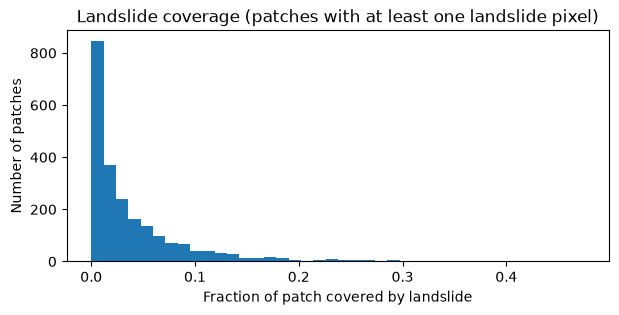

In [12]:
n = len(img_files)
fractions = np.array([read_h5(MASK_DIR / f"mask_{i}.h5").mean() for i in range(1, n + 1)])

print(f"Patches with any landslide: {(fractions > 0).sum()} of {n}")
print(f"Overall landslide pixels: {fractions.mean():.2%} of all pixels")

plt.figure(figsize=(7, 3))
plt.hist(fractions[fractions > 0], bins=40)
plt.xlabel("Fraction of patch covered by landslide")
plt.ylabel("Number of patches")
plt.title("Landslide coverage (patches with at least one landslide pixel)")
plt.show()

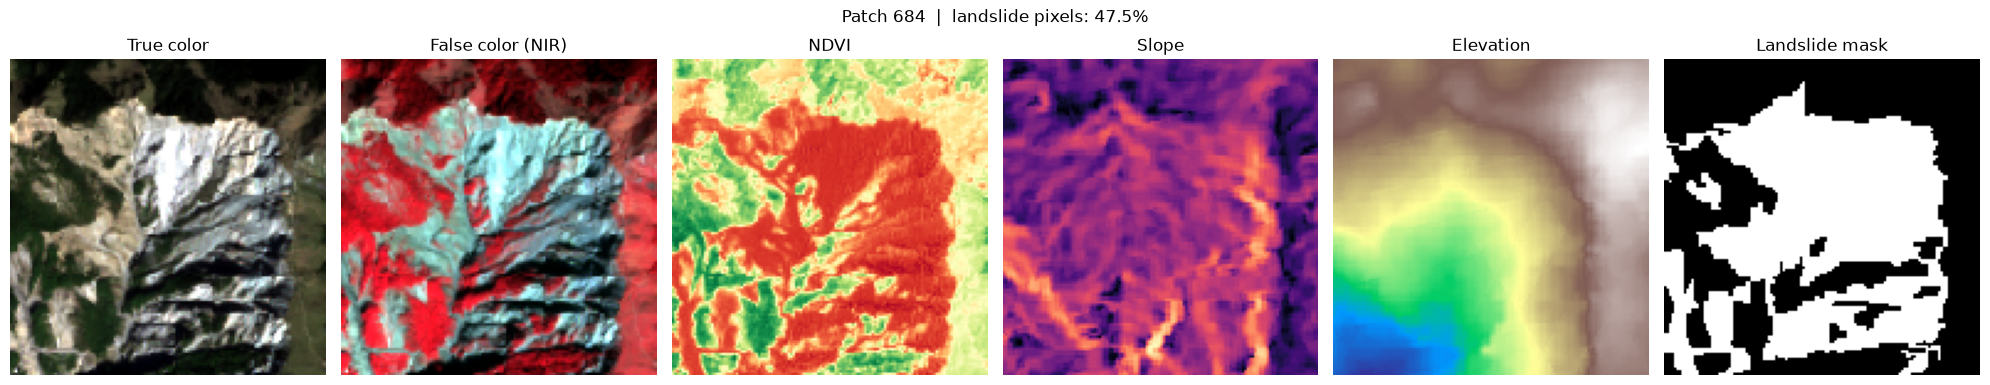

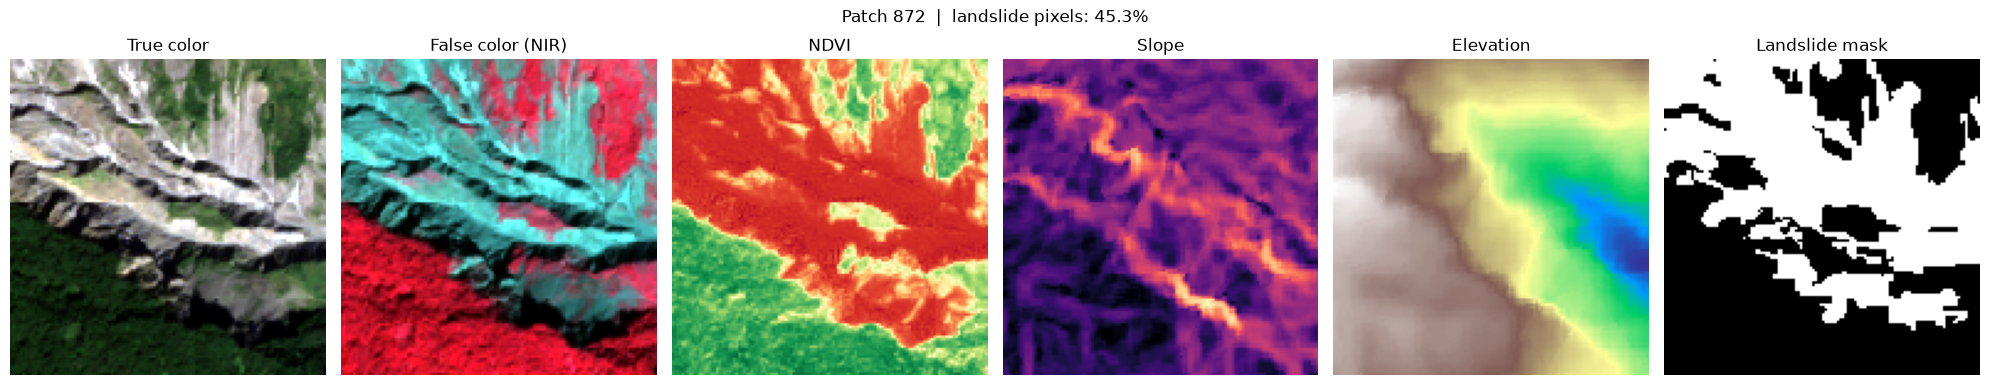

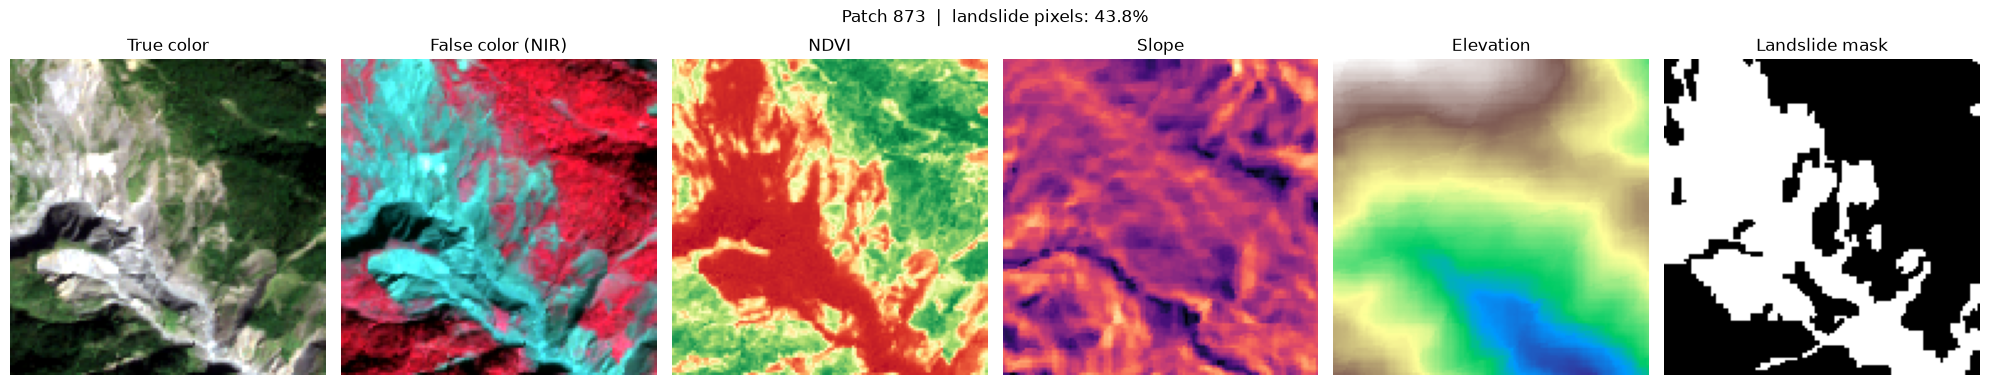

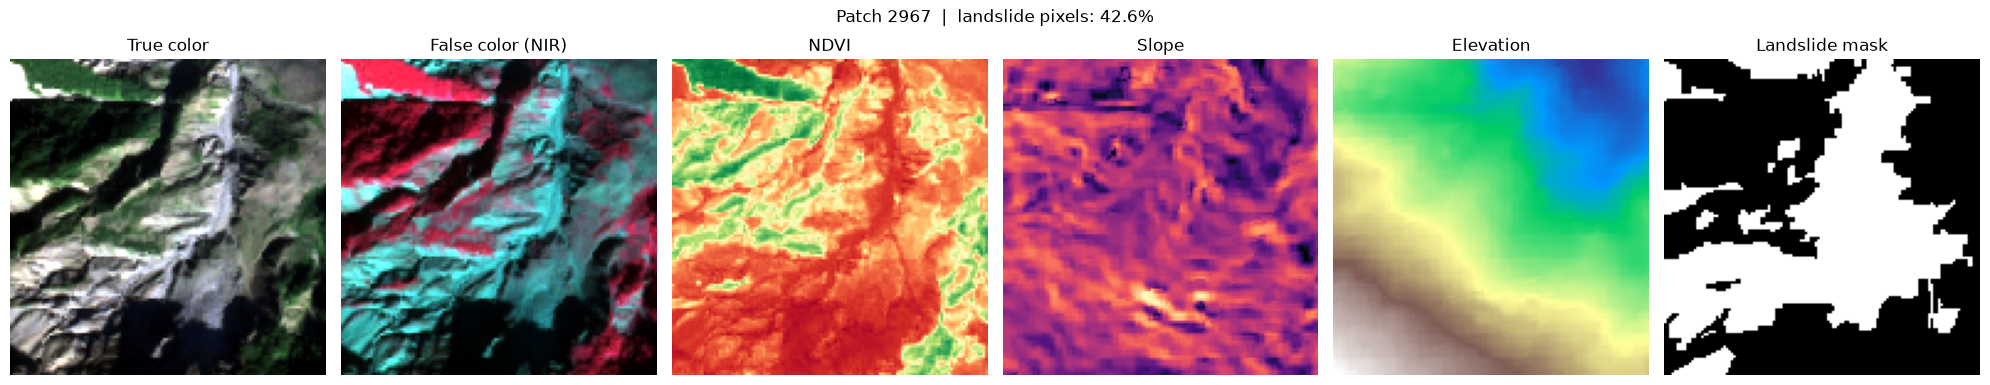

In [13]:
top = np.argsort(fractions)[::-1][:4] + 1
for i in top:
    show_patch(int(i))

## Overlay the mask on true color
This is the view you'll use later to judge your model's predictions.

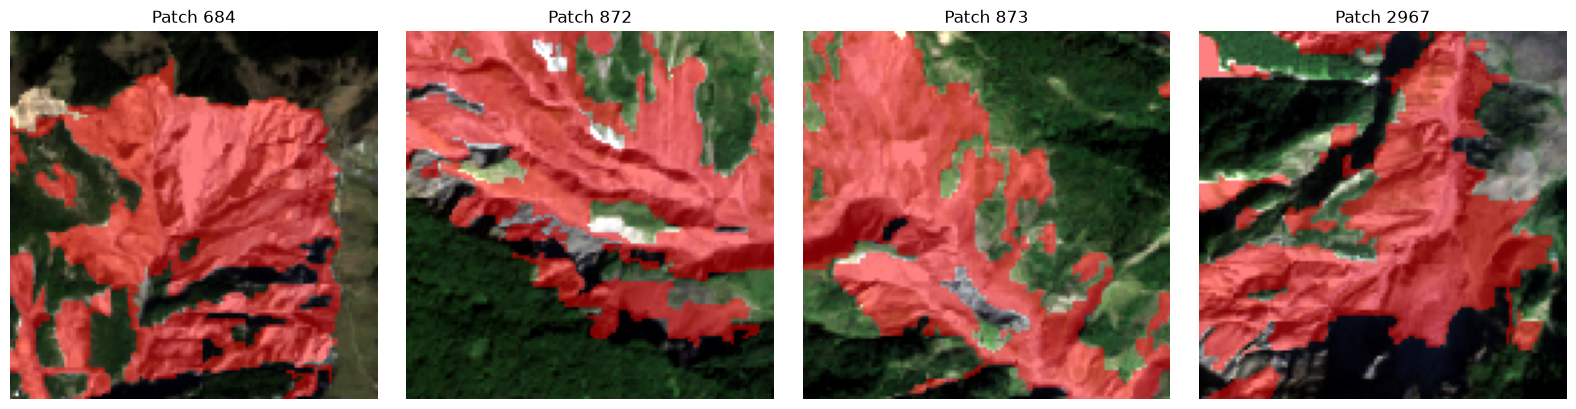

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, i in zip(axes, top):
    img, mask = load_pair(int(i))
    ax.imshow(rgb(img, [3, 2, 1]))
    ax.imshow(np.ma.masked_where(mask == 0, mask), cmap="autumn", alpha=0.5)
    ax.set_title(f"Patch {i}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Per-band statistics (needed for training)
Neural networks train better when every band is on a similar scale. These means and standard deviations get saved and reused in the training notebook.

In [15]:
rng = np.random.default_rng(0)
sample_ids = rng.choice(np.arange(1, n + 1), size=min(500, n), replace=False)
stack = np.stack([load_pair(int(i))[0] for i in sample_ids])

band_mean = stack.mean(axis=(0, 1, 2))
band_std = stack.std(axis=(0, 1, 2))

for name, m, s in zip(BAND_NAMES, band_mean, band_std):
    print(f"{name:18s} mean={m:8.3f}  std={s:8.3f}")

np.save(Path.home() / "geoai" / "band_stats.npy", np.stack([band_mean, band_std]))
print("Saved band_stats.npy")

B1 coastal         mean=   0.958  std=   0.141
B2 blue            mean=   0.945  std=   0.215
B3 green           mean=   0.961  std=   0.312
B4 red             mean=   0.972  std=   0.567
B5 red edge 1      mean=   1.035  std=   0.461
B6 red edge 2      mean=   1.044  std=   0.451
B7 red edge 3      mean=   1.036  std=   0.470
B8 NIR             mean=   1.047  std=   0.500
B9 water vapor     mean=   1.173  std=   0.517
B10 cirrus         mean=   1.198  std=   0.680
B11 SWIR 1         mean=   1.051  std=   0.534
B12 SWIR 2         mean=   1.047  std=   0.670
Slope              mean=   1.213  std=   0.684
Elevation (DEM)    mean=   1.620  std=   1.081
Saved band_stats.npy
